# Training a simple semantic-segmentation model (PyTorch + MPS)

We train a small U-Net from scratch to predict the per-pixel **semantic class**
of synthetic satellite scenes, using the masks from `mlpsyn.segmentation`.

- inputs: 64x64 RGB scenes;
- targets: 13-class label maps (class 0 = *unlabeled*, ignored by the loss);
- model: a compact U-Net (~0.33 M parameters);
- metrics: pixel accuracy and mean IoU over the classes present.

Everything runs on the Apple **MPS** device and the whole notebook finishes in a
few minutes.


## Learning objectives

By the end of this notebook you will be able to:

- build paired **(image, semantic-label)** data with `mlpsyn.segmentation`;
- implement a compact **U-Net** with skip connections;
- train it with **cross-entropy** (ignoring the background class);
- compute and interpret **per-class IoU** and **mean IoU (mIoU)**.

### Exercises

1. Why do we pass `ignore_index=0` to the loss (what is class 0)?
2. Which classes have the lowest IoU, and how does class frequency explain it?


In [1]:
import os

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")
os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ.setdefault("MKL_NUM_THREADS", "1")

import time

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

torch.manual_seed(0)
np.random.seed(0)

DEVICE = "mps" if torch.backends.mps.is_available() else "cpu"
print("torch", torch.__version__, "| device", DEVICE)
if DEVICE == "cpu":
    print("MPS not available: training will be slower (CPU fallback).")


torch 2.14.0 | device mps


## Dataset

Each image also gets a **small amount of realistic sensor noise** (light blur /
haze / Poisson-Gaussian noise) and **~20 % of the images get partial cloud
cover**; the semantic label mask is unchanged, so the model must segment
through the degradation.


In [2]:
from mlpsyn.scene import SCENES, generate_scene
from mlpsyn.segmentation import SEGMENTATION_CLASSES, semantic_mask
from mlpsyn.sensor import apply_sensor

N_SAMPLES, SIZE = 240, 64
N_VAL, N_TEST = 48, 40
scene_names = sorted(SCENES)


def degrade_image(image, rng):
    """Small realistic sensor noise; ~20% of images get partial cloud cover.

    Labels/boxes come from the clean scene, so they stay valid under the noise:
    the model just has to be robust to it. Most images are only lightly degraded.
    """
    if rng.random() < 0.2:
        return apply_sensor(
            image, rng, kind="poisson", blur_radius=0.5,
            haze_strength=0.06, cloud_coverage=rng.uniform(0.2, 0.4),
        )
    if rng.random() < 0.5:
        return apply_sensor(
            image, rng, kind="poisson" if rng.random() < 0.5 else None,
            blur_radius=rng.uniform(0.0, 0.4), haze_strength=rng.uniform(0.0, 0.06),
        )
    return image.copy()


def make_data(n_samples, size, seed=0):
    """Paired (image, semantic-label) samples with light realistic degradation."""
    rng = np.random.default_rng(seed)
    images, labels = [], []
    for _ in range(n_samples):
        scene_name = scene_names[int(rng.integers(len(scene_names)))]
        scene_seed = int(rng.integers(10_000))
        clean = generate_scene(scene_name, size=size, seed=scene_seed).image
        _, mask = semantic_mask(scene_name, size=size, seed=scene_seed)
        images.append(degrade_image(clean, rng))
        labels.append(mask)
    image_tensor = (
        np.stack(images).astype(np.float32).transpose(0, 3, 1, 2) / 255.0
    )
    label_tensor = np.stack(labels).astype(np.int64)
    return torch.from_numpy(image_tensor), torch.from_numpy(label_tensor)


started = time.time()
images, labels = make_data(N_SAMPLES, SIZE)
# train / validation (model selection) / test (reported once).
train_images, train_labels = images[: -(N_VAL + N_TEST)], labels[: -(N_VAL + N_TEST)]
val_images, val_labels = images[-(N_VAL + N_TEST): -N_TEST], labels[-(N_VAL + N_TEST): -N_TEST]
test_images, test_labels = images[-N_TEST:], labels[-N_TEST:]
print("train", tuple(train_images.shape), "val", tuple(val_images.shape),
      "test", tuple(test_images.shape))
print("generated in", round(time.time() - started, 1), "s")


train (152, 3, 64, 64) val (48, 3, 64, 64) test (40, 3, 64, 64)
generated in 41.2 s


## Prediction and target spaces, loss and metric

- **Prediction** `logits` ∈ ℝ^{B×13×64×64}; probabilities are
  `softmax(logits, dim=1)`.
- **Target** `labels` ∈ {0,…,12}^{B×64×64}; class 0 is **unlabeled** and ignored.

**Loss** — cross-entropy over the non-ignored pixels
$\Omega=\{i : y_i\neq 0\}$:

$$\mathcal{L} = -\frac{1}{|\Omega|}\sum_{i\in\Omega}\log \mathrm{softmax}(z_i)[y_i]$$

**Metrics** (with $\hat y_i=\arg\max_c z_i^c$)
- pixel accuracy $=\frac{1}{|\Omega|}\sum_{i\in\Omega}\mathbf{1}[\hat y_i=y_i]$
- $\mathrm{IoU}_c = \frac{|\{\hat y=c\}\cap\{y=c\}|}{|\{\hat y=c\}\cup\{y=c\}|}$
- $\mathrm{mIoU} = \mathrm{mean}_c\,\mathrm{IoU}_c$ over classes present in the target.


In [3]:
# Loss and metric values on toy logits / label maps (no model yet).
torch.manual_seed(0)
example_labels = torch.tensor([[[0, 1, 1, 2], [0, 1, 2, 2], [1, 1, 2, 0], [0, 2, 2, 2]]])
example_logits = torch.randn(1, 13, 4, 4)

print("cross-entropy (ignore class 0):", round(float(F.cross_entropy(example_logits, example_labels, ignore_index=0)), 3))
log_probs = F.log_softmax(example_logits, dim=1)
valid_mask = example_labels != 0
per_pixel_loss = -log_probs.gather(1, example_labels.unsqueeze(1))[:, 0]
print("manual cross-entropy:         ", round(float(per_pixel_loss[valid_mask].mean()), 3))

# A perfect prediction: huge logit on the true class (class 0 pixels are ignored).
perfect_logits = torch.full_like(example_logits, -10.0)
perfect_logits.scatter_(1, example_labels.unsqueeze(1), 10.0)
print("CE of perfect logits:         ", round(float(F.cross_entropy(perfect_logits, example_labels, ignore_index=0)), 4))

predictions = perfect_logits.argmax(1)
accuracy = (predictions[valid_mask] == example_labels[valid_mask]).float().mean()
per_class_iou = []
for class_id in range(1, 13):
    intersection = ((predictions == class_id) & (example_labels == class_id)).sum().item()
    union = ((predictions == class_id) | (example_labels == class_id)).sum().item()
    if union:
        per_class_iou.append(intersection / union)
print("pixel accuracy:", round(float(accuracy), 3), "| mIoU:", round(float(np.mean(per_class_iou)), 3))


cross-entropy (ignore class 0): 3.185
manual cross-entropy:          3.185
CE of perfect logits:          0.0
pixel accuracy: 1.0 | mIoU: 1.0


## Model: a compact U-Net

In [4]:
class SmallUNet(nn.Module):
    """Small encoder/decoder with skip connections."""

    def __init__(self, n_classes, base=20):
        super().__init__()

        def block(in_channels, out_channels, stride=1):
            return nn.Sequential(
                nn.Conv2d(in_channels, out_channels, 3, stride, 1, bias=False),
                nn.BatchNorm2d(out_channels),
                nn.ReLU(inplace=True),
                nn.Conv2d(out_channels, out_channels, 3, 1, 1, bias=False),
                nn.BatchNorm2d(out_channels),
                nn.ReLU(inplace=True),
            )

        self.encoder1 = block(3, base)
        self.encoder2 = block(base, base * 2, 2)
        self.encoder3 = block(base * 2, base * 4, 2)
        self.encoder4 = block(base * 4, base * 4, 2)
        self.decoder3 = block(base * 4 + base * 4, base * 2)
        self.decoder2 = block(base * 2 + base * 2, base)
        self.decoder1 = block(base + base, base)
        self.head = nn.Conv2d(base, n_classes, 1)

    def forward(self, image_batch):
        # enc1..enc4: feature maps at decreasing resolution.
        enc1 = self.encoder1(image_batch)
        enc2 = self.encoder2(enc1)
        enc3 = self.encoder3(enc2)
        enc4 = self.encoder4(enc3)
        up3 = F.interpolate(enc4, size=enc3.shape[-2:], mode="nearest")
        dec3 = self.decoder3(torch.cat([up3, enc3], 1))
        up2 = F.interpolate(dec3, size=enc2.shape[-2:], mode="nearest")
        dec2 = self.decoder2(torch.cat([up2, enc2], 1))
        up1 = F.interpolate(dec2, size=enc1.shape[-2:], mode="nearest")
        dec1 = self.decoder1(torch.cat([up1, enc1], 1))
        return self.head(dec1)


model = SmallUNet(len(SEGMENTATION_CLASSES)).to(DEVICE)
n_parameters = sum(p.numel() for p in model.parameters())
print(f"{n_parameters/1e3:.1f} k parameters")


329.6 k parameters


## Training loop

In [5]:
optimizer = torch.optim.AdamW(model.parameters(), lr=2e-3)
EPOCHS, BATCH_SIZE = 30, 16
train_images_device = train_images.to(DEVICE)
train_labels_device = train_labels.to(DEVICE)
history = []


def evaluate(images_split, labels_split):
    """Pixel accuracy, mean IoU and per-class IoU on one split."""
    model.eval()
    with torch.no_grad():
        predictions = model(images_split.to(DEVICE)).argmax(1).cpu()
    valid_mask = labels_split > 0
    accuracy = (predictions[valid_mask] == labels_split[valid_mask]).float().mean().item()
    # mean IoU over classes present in the target, plus a per-class list that
    # stays aligned with class ids 1..12 (0.0 for absent classes).
    mean_iou_values, per_class_iou = [], []
    for class_id in range(1, len(SEGMENTATION_CLASSES)):
        target_class = labels_split == class_id
        predicted_class = predictions == class_id
        union = (target_class | predicted_class).sum().item()
        iou = (target_class & predicted_class).sum().item() / union if union else 0.0
        per_class_iou.append(iou)
        if union:
            mean_iou_values.append(iou)
    return accuracy, float(np.mean(mean_iou_values)), per_class_iou


started = time.time()
for epoch in range(EPOCHS):
    model.train()
    permutation = torch.randperm(len(train_images_device), device=DEVICE)
    running_loss = 0.0
    # Cross-entropy over valid pixels only (class 0 is background/ignore).
    for start in range(0, len(train_images_device), BATCH_SIZE):
        batch_indices = permutation[start : start + BATCH_SIZE]
        optimizer.zero_grad()
        loss = F.cross_entropy(
            model(train_images_device[batch_indices]),
            train_labels_device[batch_indices],
            ignore_index=0,
        )
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * len(batch_indices)
    if epoch % 4 == 3 or epoch == EPOCHS - 1:
        accuracy, mean_iou, _ = evaluate(val_images, val_labels)
        history.append((epoch, running_loss / len(train_images_device), accuracy, mean_iou))
        print(
            f"epoch {epoch:2d} | loss {running_loss/len(train_images_device):.3f}"
            f" | acc {accuracy:.3f} | mIoU {mean_iou:.3f} | {time.time()-started:.0f}s"
        )
print("training time:", round(time.time() - started, 1), "s")


epoch  3 | loss 1.464 | acc 0.586 | mIoU 0.301 | 3s


epoch  7 | loss 1.174 | acc 0.754 | mIoU 0.444 | 6s


epoch 11 | loss 0.867 | acc 0.801 | mIoU 0.503 | 8s


epoch 15 | loss 0.769 | acc 0.778 | mIoU 0.498 | 11s


epoch 19 | loss 0.651 | acc 0.805 | mIoU 0.539 | 13s


epoch 23 | loss 0.637 | acc 0.804 | mIoU 0.547 | 16s


epoch 27 | loss 0.599 | acc 0.842 | mIoU 0.591 | 18s


epoch 29 | loss 0.569 | acc 0.854 | mIoU 0.614 | 19s
training time: 19.5 s


## Evaluation on held-out scenes

In [6]:
accuracy, mean_iou, per_class_iou = evaluate(val_images, val_labels)
test_accuracy, test_iou, _ = evaluate(test_images, test_labels)
print(f"validation pixel accuracy {accuracy:.3f} | mean IoU {mean_iou:.3f}")
print(f"test       pixel accuracy {test_accuracy:.3f} | mean IoU {test_iou:.3f}   <- reported once")
classes_present = list(range(1, len(SEGMENTATION_CLASSES)))
print(
    "per-class IoU:",
    [(SEGMENTATION_CLASSES[class_id], round(value, 3)) for class_id, value in zip(classes_present, per_class_iou)],
)


validation pixel accuracy 0.854 | mean IoU 0.614
test       pixel accuracy 0.846 | mean IoU 0.619   <- reported once
per-class IoU: [('grassland', 0.77), ('cropland', 0.827), ('bare_soil', 0.687), ('vegetation', 0.885), ('water', 0.859), ('built', 0.773), ('road', 0.577), ('rock', 0.433), ('sand', 0.912), ('snow', 0.0), ('gravel', 0.332), ('wetland', 0.311)]


## Class colour legend

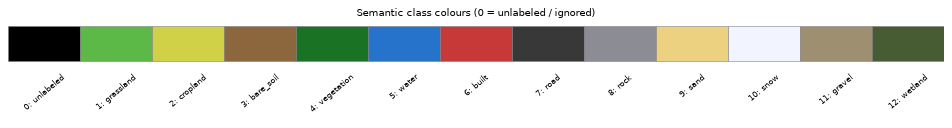

In [7]:
from mlpsyn.segmentation import CLASS_COLORS

fig, ax = plt.subplots(figsize=(12, 1.7), dpi=80)
for class_id, class_name in enumerate(SEGMENTATION_CLASSES):
    color = (0.0, 0.0, 0.0) if class_id == 0 else CLASS_COLORS[class_name]
    ax.add_patch(plt.Rectangle((class_id, 0), 1, 1, facecolor=color, edgecolor="grey", linewidth=0.5))
    ax.text(class_id + 0.5, -0.35, f"{class_id}: {class_name}", ha="center", va="top", rotation=40, fontsize=7)
ax.set_xlim(0, len(SEGMENTATION_CLASSES))
ax.set_ylim(-1.7, 1.1)
ax.axis("off")
ax.set_title("Semantic class colours (0 = unlabeled / ignored)", fontsize=9)
plt.tight_layout()
plt.show()


## Prediction grids

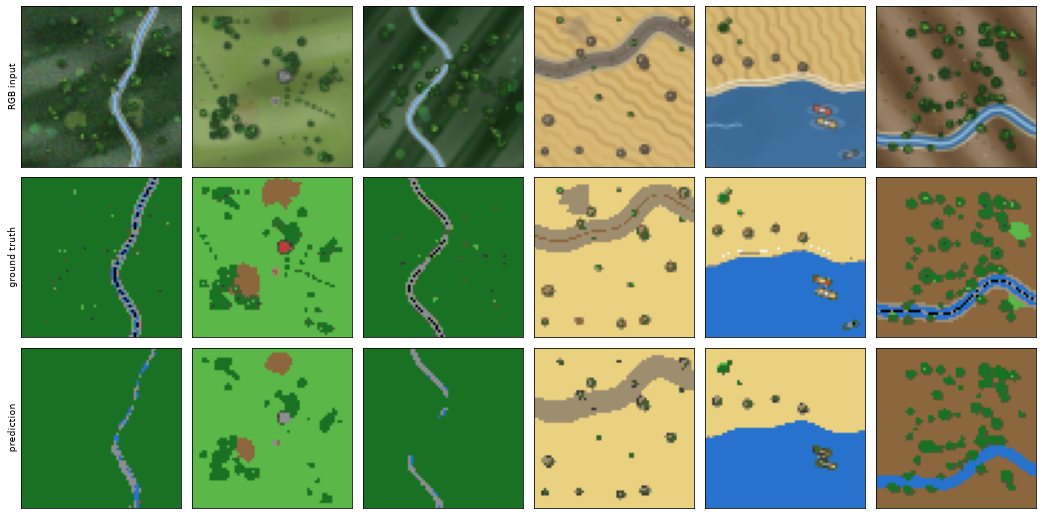

In [8]:
from mlpsyn.segmentation import CLASS_COLORS

palette = np.array(
    [[0, 0, 0]] + [[int(255 * c) for c in CLASS_COLORS[name]] for name in SEGMENTATION_CLASSES[1:]],
    dtype=np.uint8,
)
model.eval()
with torch.no_grad():
    predictions = model(val_images[:6].to(DEVICE)).argmax(1).cpu()

fig, axes = plt.subplots(3, 6, figsize=(15, 7.5), dpi=70)
for sample_idx in range(6):
    axes[0, sample_idx].imshow(val_images[sample_idx].permute(1, 2, 0))
    axes[1, sample_idx].imshow(palette[val_labels[sample_idx].numpy()])
    axes[2, sample_idx].imshow(palette[predictions[sample_idx].numpy()])
for row, title in enumerate(["RGB input", "ground truth", "prediction"]):
    axes[row, 0].set_ylabel(title, fontsize=9)
for ax in axes.ravel():
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.show()


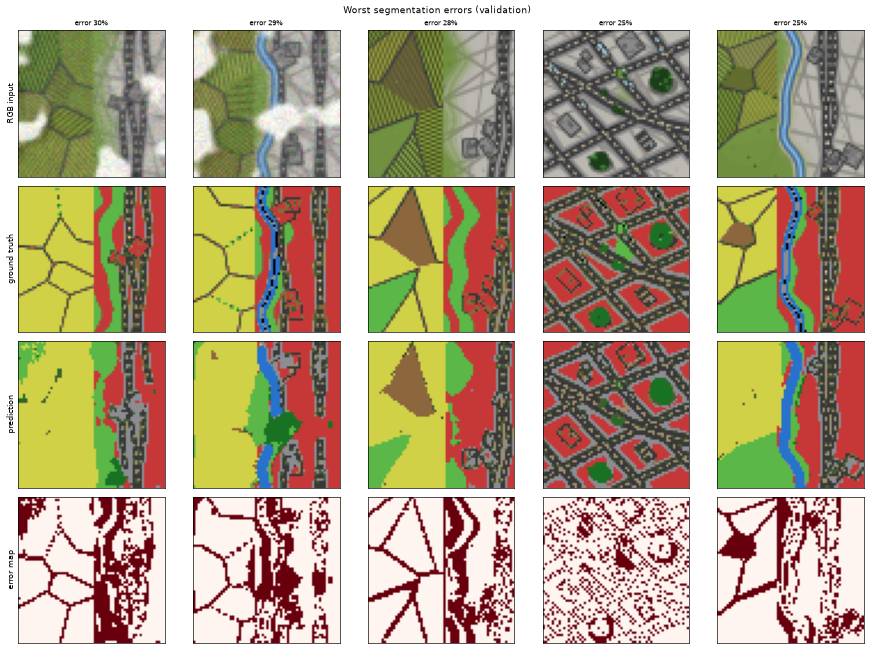

In [9]:
# Failure gallery: the five validation scenes with the largest pixel-error
# fraction, with an explicit error map (red = misclassified, valid pixels only).
model.eval()
with torch.no_grad():
    val_predictions = model(val_images.to(DEVICE)).argmax(1).cpu()
error_fraction = []
for sample_idx in range(len(val_images)):
    valid = val_labels[sample_idx] > 0
    error_fraction.append(float(((val_predictions[sample_idx] != val_labels[sample_idx]) & valid).float().mean()))
worst = np.argsort(error_fraction)[::-1][:5]

fig, axes = plt.subplots(4, 5, figsize=(15, 11), dpi=60)
for col, sample_idx in enumerate(worst):
    axes[0, col].imshow(val_images[sample_idx].permute(1, 2, 0))
    axes[0, col].set_title(f"error {error_fraction[sample_idx]:.0%}", fontsize=8)
    axes[1, col].imshow(palette[val_labels[sample_idx].numpy()])
    axes[2, col].imshow(palette[val_predictions[sample_idx].numpy()])
    error_map = (val_predictions[sample_idx] != val_labels[sample_idx]).numpy() & (val_labels[sample_idx].numpy() > 0)
    axes[3, col].imshow(error_map, cmap="Reds", vmin=0, vmax=1)
for ax, title in zip(axes[:, 0], ["RGB input", "ground truth", "prediction", "error map"]):
    ax.set_ylabel(title, fontsize=9)
for ax in axes.ravel():
    ax.set_xticks([]); ax.set_yticks([])
plt.suptitle("Worst segmentation errors (validation)", fontsize=11)
plt.tight_layout()
plt.show()


This notebook segments **64x64** scenes with light sensor noise and ~20 % cloud
cover, and the semantic mask is evaluated even under clouds that hide the
ground. Perfect per-pixel accuracy would require seeing through clouds.

### Interpreting these numbers

The scores above are measured on **deliberately hard** imagery, not a clean
benchmark, and that is the point of a synthetic dataset:

- **High accuracy on clean images can mislead.** A segmenter can look
  near-perfect on pristine renders and still fail on the first cloudy or blurry
  acquisition; a slightly lower number on degraded data is the more honest one.
- **The degradation bounds what any model can recover.** Under cloud cover the
  ground is physically hidden, and structures only a few pixels wide (a thin
  track, a small pool) cannot be segmented reliably. No architecture beats that
  ceiling; it is a property of the data, not a bug.
- **Some errors are irreducible.** A boundary between two materials is a
  judgement call even for a human annotator.
- **Report per-class IoU, not just accuracy.** The mean IoU exposes the rare,
  hard classes that a single pixel-accuracy number hides.

The takeaway is not "the model is bad", but "these metrics quantify **robustness
under realistic conditions**"; improving them means better resolution or priors.
